In [ ]:

# OTT Streaming Content Trend Analysis
# Created by: Diya Goel

print("OTT Streaming Content Trend Analysis")
print("Project started successfully!")
print("Created by: Diya Goel")


OTT Streaming Content Trend Analysis
Project started successfully!
Created by: Diya Goel


In [ ]:
!pip install pandas matplotlib seaborn

In [ ]:

import pandas as pd

df = pd.read_csv('/content/netflix_titles.csv')

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:

#  Understand the Netflix Dataset

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nContent Types:")
print(df["type"].value_counts())


Dataset Shape:
(8807, 12)

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing Values in Each Column:
show_id          

In [ ]:

#  Initial Business Overview

print("Unique Titles:", df["title"].nunique())

print("\nContent Type Percentage:")
print(
    (df["type"].value_counts(normalize=True) * 100).round(2)
)

print("\nRelease Year Range:")
print(df["release_year"].min(), "-", df["release_year"].max())

print("\nTop 10 Content-Producing Countries:")
print(df["country"].value_counts().head(10))

print("\nTop 10 Listed Genres:")
print(df["listed_in"].value_counts().head(10))


Unique Titles: 8807

Content Type Percentage:
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64

Release Year Range:
1925 - 2021

Top 10 Content-Producing Countries:
country
United States     2818
India              972
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Egypt              106
Name: count, dtype: int64

Top 10 Listed Genres:
listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            220
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, Int

In [ ]:
# Data Cleaning

# Keep original data safe
df_clean = df.copy()

# Fill missing text values without deleting useful records
columns_to_fill = [
    "director", "cast", "country", "rating", "duration"
]

for col in columns_to_fill:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Convert date_added into a proper date format
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"],
    format="mixed",
    errors="coerce"
)

# Remove accidental extra spaces from text columns
text_columns = df_clean.select_dtypes(
    include="object"
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Check cleaning results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())

print("\nData cleaning completed successfully!")


Original dataset shape: (8807, 12)
Cleaned dataset shape: (8807, 12)

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Duplicate rows after cleaning:
0

Data cleaning completed successfully!


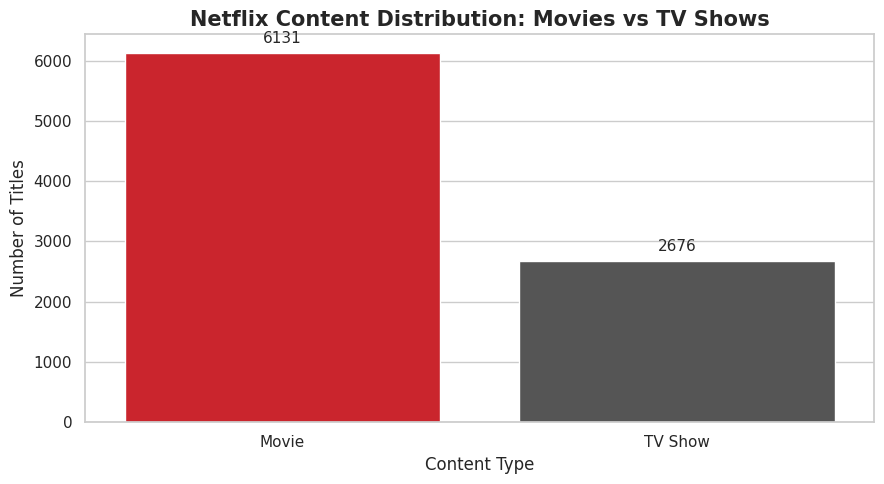

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
#
# Professional chart styling
sns.set_theme(style="whitegrid")

# Count movies and TV shows
content_counts = df_clean["type"].value_counts()

# Create chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=content_counts.index,
    y=content_counts.values,
    hue=content_counts.index,
    palette=["#E50914", "#555555"],
    legend=False
)

# Add values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=5, fontsize=11)

plt.title(
    "Netflix Content Distribution: Movies vs TV Shows",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Content Type", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.tight_layout()
plt.show()


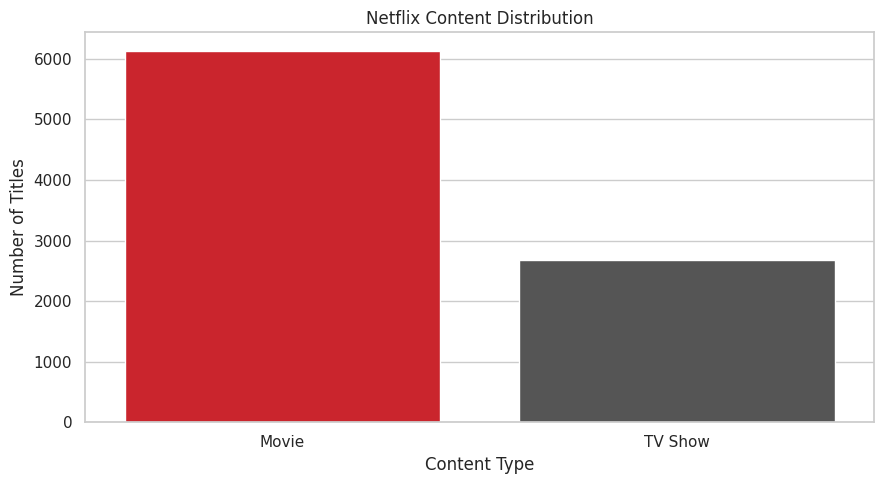

In [ ]:

plt.figure(figsize=(9, 5))

sns.barplot(
    x=content_counts.index,
    y=content_counts.values,
    hue=content_counts.index,
    palette=["#E50914", "#555555"],
    legend=False
)

plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()

plt.savefig(
    "content_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


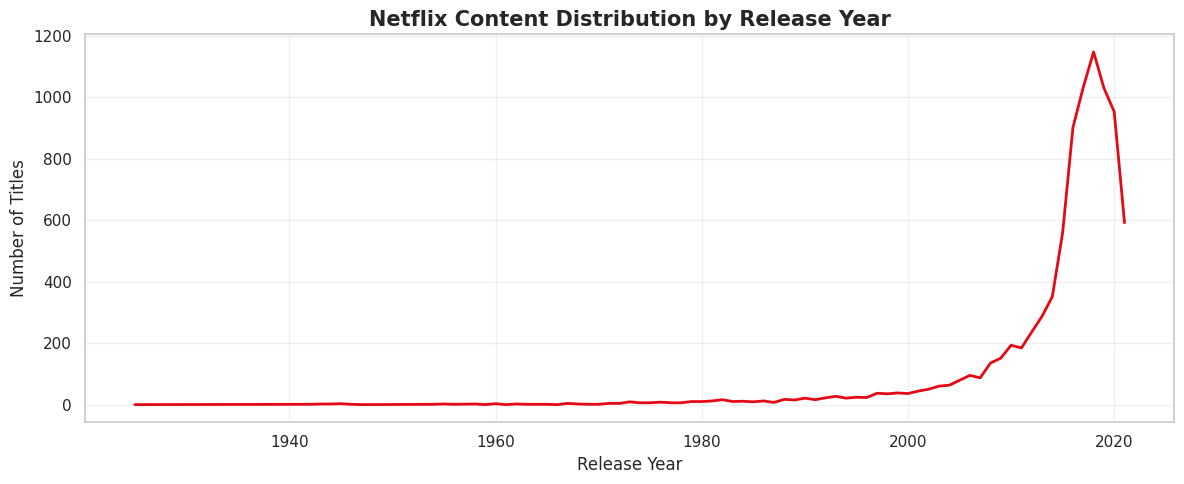

In [ ]:

# Chart 2: Content Releases by Year

yearly_content = (
    df_clean["release_year"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_content.index,
    yearly_content.values,
    color="#E50914",
    linewidth=2
)

plt.title(
    "Netflix Content Distribution by Release Year",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "content_by_release_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


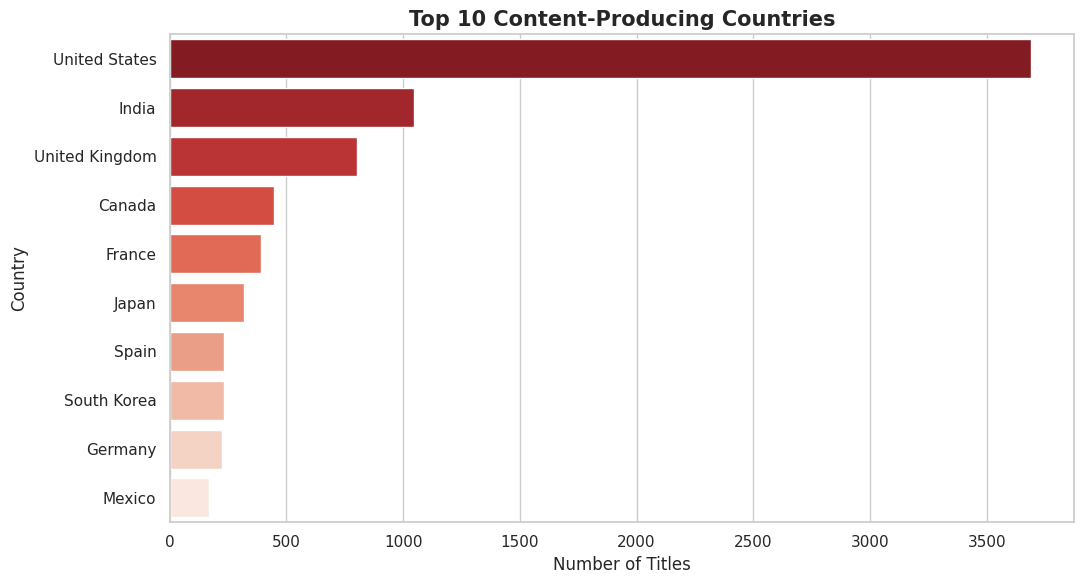

In [ ]:

# Chart 3: Top 10 Content-Producing Countries

country_counts = (
    df_clean["country"]
    .str.split(", ")
    .explode()
)

country_counts = country_counts[
    country_counts != "Unknown"
]

top_countries = country_counts.value_counts().head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    hue=top_countries.index,
    palette="Reds_r",
    legend=False
)

plt.title(
    "Top 10 Content-Producing Countries",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Country", fontsize=12)
plt.tight_layout()

plt.savefig(
    "top_10_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


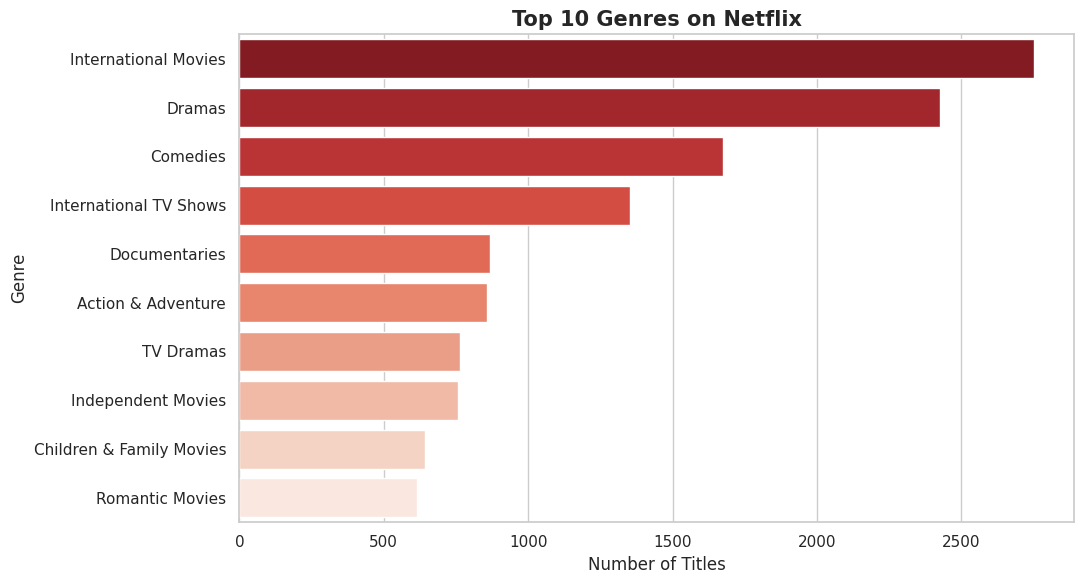

Top 10 Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [ ]:

# Chart 4: Top 10 Genres on Netflix

genre_counts = (
    df_clean["listed_in"]
    .str.split(", ")
    .explode()
)

top_genres = genre_counts.value_counts().head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    hue=top_genres.index,
    palette="Reds_r",
    legend=False
)

plt.title(
    "Top 10 Genres on Netflix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Genre", fontsize=12)
plt.tight_layout()

plt.savefig(
    "top_10_genres.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Top 10 Genres:")
print(top_genres)


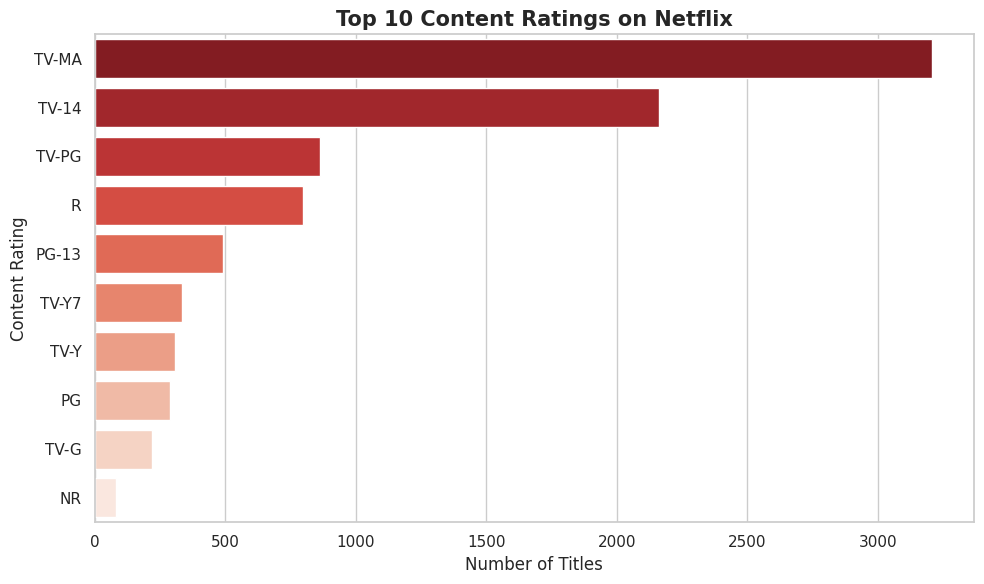

Rating Counts:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


In [ ]:

# Chart 5: Netflix Content Ratings Distribution

rating_counts = (
    df_clean["rating"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index,
    hue=rating_counts.index,
    palette="Reds_r",
    legend=False
)

plt.title(
    "Top 10 Content Ratings on Netflix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Content Rating", fontsize=12)
plt.tight_layout()

plt.savefig(
    "content_ratings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Rating Counts:")
print(rating_counts)


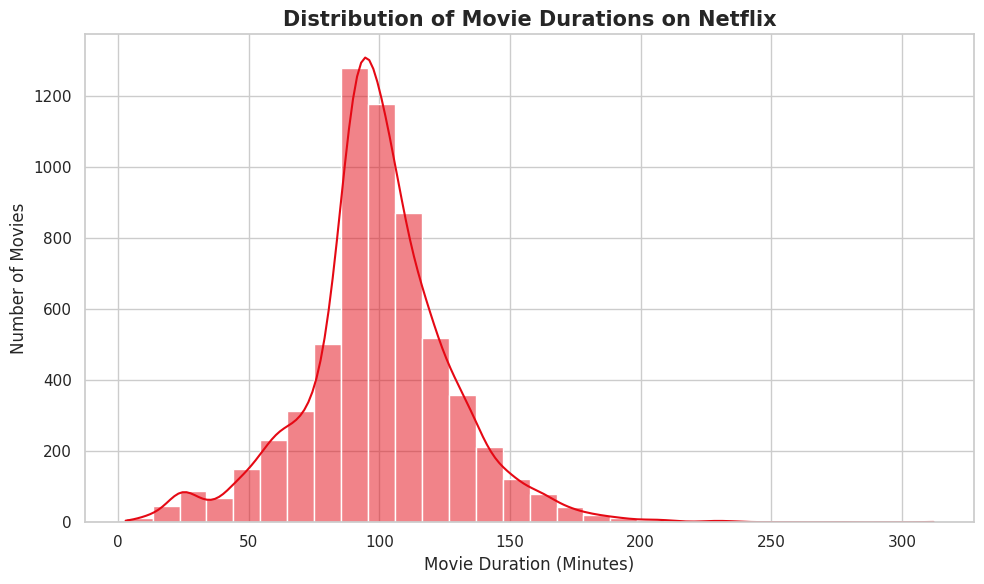

Movies with available duration: 6128
Average movie duration: 99.58 minutes
Median movie duration: 98.0 minutes


In [ ]:

# Chart 6: Movie Duration Analysis

# Select movies and extract duration in minutes
movies = df_clean[df_clean["type"] == "Movie"].copy()

movies["duration_minutes"] = pd.to_numeric(
    movies["duration"]
    .str.extract(r"(\d+)")
    [0],
    errors="coerce"
)

# Remove unavailable duration values for this chart only
movie_duration = movies["duration_minutes"].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(
    movie_duration,
    bins=30,
    kde=True,
    color="#E50914"
)

plt.title(
    "Distribution of Movie Durations on Netflix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Movie Duration (Minutes)", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)
plt.tight_layout()

plt.savefig(
    "movie_duration_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Movies with available duration:", len(movie_duration))
print("Average movie duration:", round(movie_duration.mean(), 2), "minutes")
print("Median movie duration:", round(movie_duration.median(), 2), "minutes")
